# S&P 500 Stock Analysis and Next-Day Prediction

**Goal:** explore 5 years of S&P 500 stock data, test the statistical properties of daily returns, and find out what can and cannot be predicted about Apple's next-day and next-week price movements.

**Data:** S&P 500 stock data (Kaggle): daily prices and volumes for 505 companies, February 2013 – February 2018 (619,029 rows after cleaning).

**Sections:**
1. Data cleaning and exploration
2. First model: logistic regression on past returns
3. Statistics on returns: fat tails and autocorrelation
4. Improved model: new features and a random forest
5. Predicting volatility: volatility clustering and regression models
6. Conclusion

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/camnugent/sandp500/merge.sh
/kaggle/input/datasets/camnugent/sandp500/getSandP.py
/kaggle/input/datasets/camnugent/sandp500/all_stocks_5yr.csv
/kaggle/input/datasets/camnugent/sandp500/individual_stocks_5yr/__MACOSX/individual_stocks_5yr/._.DS_Store
/kaggle/input/datasets/camnugent/sandp500/individual_stocks_5yr/__MACOSX/individual_stocks_5yr/._ABC_data.csv
/kaggle/input/datasets/camnugent/sandp500/individual_stocks_5yr/__MACOSX/individual_stocks_5yr/._AAPL_data.csv
/kaggle/input/datasets/camnugent/sandp500/individual_stocks_5yr/__MACOSX/individual_stocks_5yr/._A_data.csv
/kaggle/input/datasets/camnugent/sandp500/individual_stocks_5yr/__MACOSX/individual_stocks_5yr/._MAS_data.csv
/kaggle/input/datasets/camnugent/sandp500/individual_stocks_5yr/individual_stocks_5yr/CL_data.csv
/kaggle/input/datasets/camnugent/sandp500/individual_stocks_5yr/individual_stocks_5yr/FDX_data.csv
/kaggle/input/datasets/camnugent/sandp500/individual_stocks_5yr/individual_stocks_5yr/AMAT_

In [2]:
import pandas as pd

df = pd.read_csv("/kaggle/input/datasets/camnugent/sandp500/all_stocks_5yr.csv")
print(df.shape)
df.head()

(619040, 7)


,date,open,high,low,close,volume,Name
0,2013-02-08,15.07,15.12,14.63,14.75,8407500,AAL
1,2013-02-11,14.89,15.01,14.26,14.46,8882000,AAL
2,2013-02-12,14.45,14.51,14.10,14.27,8126000,AAL
3,2013-02-13,14.30,14.94,14.25,14.66,10259500,AAL
4,2013-02-14,14.94,14.96,13.16,13.99,31879900,AAL


In [3]:
# Convert the date column to real dates
df["date"] = pd.to_datetime(df["date"])

# Basic facts about the data
print("Companies:", df["Name"].nunique())
print("From", df["date"].min().date(), "to", df["date"].max().date())

# Check for missing values
print(df.isnull().sum())

Companies: 505
From 2013-02-08 to 2018-02-07
date       0
open      11
high       8
low        8
close      0
volume     0
Name       0
dtype: int64


Rows after cleaning: 619029


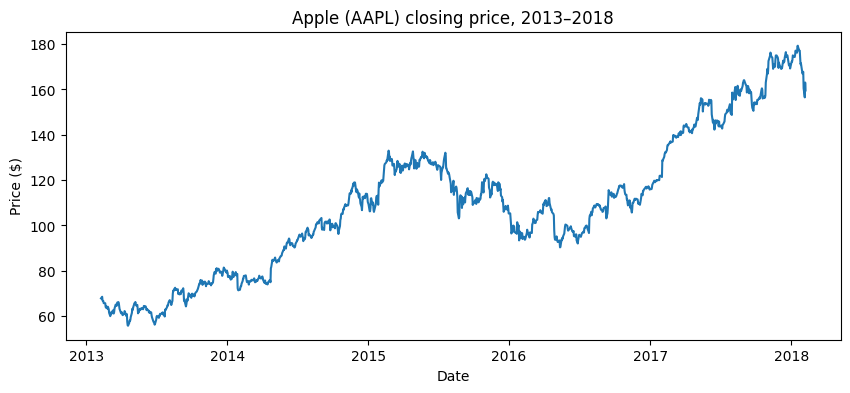

In [4]:
import matplotlib.pyplot as plt

# Remove the few rows with missing values
df = df.dropna()
print("Rows after cleaning:", len(df))

# Chart: Apple's closing price over 5 years
aapl = df[df["Name"] == "AAPL"]
plt.figure(figsize=(10, 4))
plt.plot(aapl["date"], aapl["close"])
plt.title("Apple (AAPL) closing price, 2013–2018")
plt.xlabel("Date")
plt.ylabel("Price ($)")
plt.show()

## Cleaning and first look
Removed 11 rows with missing prices (out of 619,040).
Apple's closing price rose from about 60 USD in 2013 to about 175 USD in early 2018, with a dip during 2016.

In [5]:
from sklearn.linear_model import LogisticRegression

aapl = df[df["Name"] == "AAPL"].copy()
aapl["return"] = aapl["close"].pct_change()          # daily % change
for lag in range(1, 6):
    aapl[f"lag_{lag}"] = aapl["return"].shift(lag)   # previous 5 days
aapl["next_return"] = aapl["return"].shift(-1)       # tomorrow's change
aapl = aapl.dropna()
aapl["target"] = (aapl["next_return"] > 0).astype(int)  # 1 = up, 0 = down

features = ["return"] + [f"lag_{i}" for i in range(1, 6)]
split = int(len(aapl) * 0.8)                         # first 80% to train
train, test = aapl[:split], aapl[split:]             # last 20% to test

model = LogisticRegression()
model.fit(train[features], train["target"])
print("Model accuracy:", round(model.score(test[features], test["target"]), 3))
print("Always-guess-up accuracy:", round(test["target"].mean(), 3))

Model accuracy: 0.526
Always-guess-up accuracy: 0.526


## Prediction model
Goal: predict whether Apple's price goes up or down the next day, using the last 5 days of price changes.
Method: logistic regression, trained on the first 80% of days and tested on the last 20% (split by time, so the model never sees the future).
Result: 52.6% accuracy, exactly the same as always guessing "up". The model learned nothing useful from past price changes, which suggests short-term price movements are close to random.

In [6]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# Find the data file automatically
path = None
for root, dirs, files in os.walk('/kaggle/input'):
    for f in files:
        if f == 'all_stocks_5yr.csv':
            path = os.path.join(root, f)
print('File:', path)

data = pd.read_csv(path, parse_dates=['date']).dropna()
data = data.sort_values(['Name', 'date'])

# Daily return = % change in closing price from the day before, per company
data['return'] = data.groupby('Name')['close'].pct_change()

aapl = data[data['Name'] == 'AAPL']['return'].dropna()
print(aapl.describe())

File: /kaggle/input/datasets/camnugent/sandp500/all_stocks_5yr.csv
count    1258.000000
mean        0.000786
std         0.014593
min        -0.079927
25%        -0.006397
50%         0.000435
75%         0.008631
max         0.081982
Name: return, dtype: float64


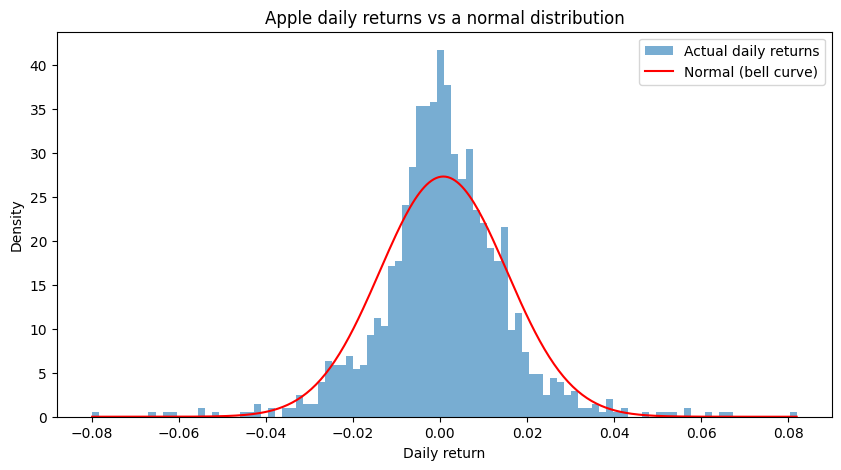

In [7]:
plt.figure(figsize=(10, 5))
plt.hist(aapl, bins=100, density=True, alpha=0.6, label='Actual daily returns')
x = np.linspace(aapl.min(), aapl.max(), 300)
plt.plot(x, stats.norm.pdf(x, aapl.mean(), aapl.std()), 'r', label='Normal (bell curve)')
plt.title('Apple daily returns vs a normal distribution')
plt.xlabel('Daily return')
plt.ylabel('Density')
plt.legend()
plt.show()

In [8]:
print('Skewness:', round(stats.skew(aapl), 3))
print('Excess kurtosis:', round(stats.kurtosis(aapl), 3))

jb_stat, jb_p = stats.jarque_bera(aapl)
print('Jarque-Bera p-value:', jb_p)

z = (aapl - aapl.mean()) / aapl.std()
actual = (z.abs() > 3).sum()
expected = len(aapl) * 2 * stats.norm.sf(3)
print(f'Extreme days (beyond 3 standard deviations): {actual}, a normal curve would expect {expected:.1f}')

Skewness: 0.012
Excess kurtosis: 3.765
Jarque-Bera p-value: 4.550782459057792e-162
Extreme days (beyond 3 standard deviations): 19, a normal curve would expect 3.4


Apple: correlation between yesterday and today: 0.0291
count    505.000000
mean      -0.009817
std        0.043800
min       -0.354853
25%       -0.034655
50%       -0.009716
75%        0.018630
max        0.173375
Name: return, dtype: float64


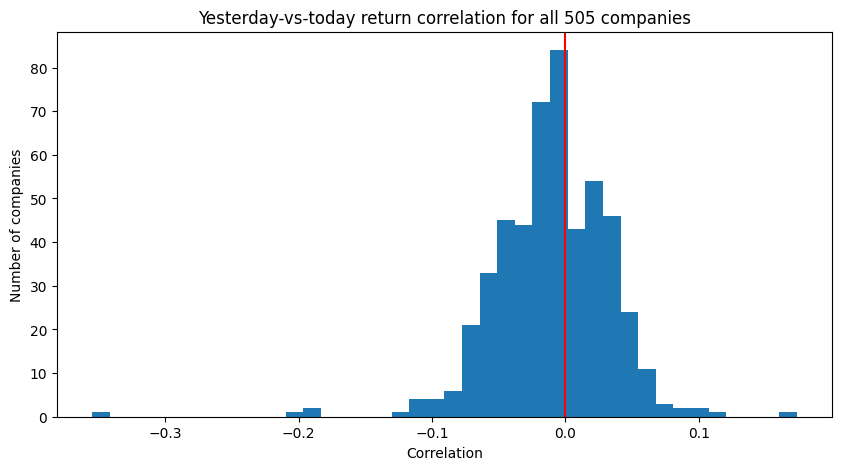

In [9]:
print('Apple: correlation between yesterday and today:', round(aapl.autocorr(lag=1), 4))

all_lag1 = data.groupby('Name')['return'].apply(lambda r: r.dropna().autocorr(lag=1))
print(all_lag1.describe())

plt.figure(figsize=(10, 5))
plt.hist(all_lag1.dropna(), bins=40)
plt.axvline(0, color='red')
plt.title('Yesterday-vs-today return correlation for all 505 companies')
plt.xlabel('Correlation')
plt.ylabel('Number of companies')
plt.show()

## Findings: Statistics on Returns

1. Returns are not normally distributed.
Apple's daily returns (1,258 trading days) average about +0.08% with a standard deviation of about 1.46%. They are almost perfectly symmetric (skewness 0.01), but they have fat tails: the excess kurtosis is 3.77, and a normal distribution would have 0. The Jarque-Bera test strongly rejects normality (p ≈ 4.6 × 10⁻¹⁶²).

2. Extreme days happen far more often than expected.
There were 19 days with moves beyond 3 standard deviations, compared with only 3.4 that a normal distribution would predict, about 5.6 times as many. The histogram shows this too: a taller, narrower peak than the bell curve, with more days far out in the tails. Models that assume normal returns underestimate risk.

3. Yesterday's return barely predicts today's.
Apple's lag-1 autocorrelation is only 0.029. Across all 505 companies, the median is −0.0097, and half of all stocks fall between −0.035 and 0.019. There is a very slight tendency for moves to reverse the next day, but it is tiny. A few companies show larger values, which could be worth checking for data issues or unusual events.

4. How this connects to the model.
Near-zero autocorrelation explains why the logistic regression could not beat the "always up" baseline (52.6%): past daily returns contain almost no information about the next day's direction. To improve predictions, the model would need other information, such as trading volume, market-wide movements or news.

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score

# Whole-market return each day = average return of all 505 stocks
market = data.groupby('date')['return'].mean().rename('market_return')

df = data[data['Name'] == 'AAPL'].set_index('date').join(market)

df['ret_5'] = df['close'].pct_change(5)                               # last 5 days' return
df['ma_ratio'] = df['close'] / df['close'].rolling(20).mean() - 1     # price vs 20-day average
df['volatility_10'] = df['return'].rolling(10).std()                 # recent volatility
df['volume_change'] = df['volume'].pct_change()                      # change in trading volume
df['next_return'] = df['return'].shift(-1)                           # tomorrow's return

df = df.dropna()
df['target'] = (df['next_return'] > 0).astype(int)                  # 1 = up tomorrow, 0 = down

print(df.shape)
df[['return', 'ret_5', 'ma_ratio', 'volatility_10', 'volume_change', 'market_return', 'target']].head()

(1239, 14)


,return,ret_5,ma_ratio,volatility_10,volume_change,market_return,target
date,,,,,,,
2013-03-08,0.002642,0.002903,-0.037376,0.017258,-0.163586,0.006198,1
2013-03-11,0.014246,0.042423,-0.019607,0.017427,0.208654,0.002554,0
2013-03-12,-0.021559,-0.006295,-0.035181,0.017664,-0.016942,-0.002200,0
2013-03-13,-0.000186,0.006315,-0.031045,0.017607,-0.128146,0.004086,1
2013-03-14,0.009689,0.004454,-0.017824,0.018027,-0.251893,0.005155,1


In [11]:
features = ['return', 'ret_5', 'ma_ratio', 'volatility_10', 'volume_change', 'market_return']

split = int(len(df) * 0.8)           # first 80% of dates to train, last 20% to test
train, test = df.iloc[:split], df.iloc[split:]
X_train, y_train = train[features], train['target']
X_test, y_test = test[features], test['target']

baseline = y_test.mean()             # accuracy of always guessing "up"

log_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
log_model.fit(X_train, y_train)

rf_model = RandomForestClassifier(n_estimators=300, max_depth=4, random_state=42)
rf_model.fit(X_train, y_train)

print(f'Test period: {test.index.min().date()} to {test.index.max().date()}')
print(f'Always-up baseline:  {baseline:.3f}')
print(f'Logistic regression: {accuracy_score(y_test, log_model.predict(X_test)):.3f}')
print(f'Random forest:       {accuracy_score(y_test, rf_model.predict(X_test)):.3f}')

Test period: 2017-02-13 to 2018-02-06
Always-up baseline:  0.524
Logistic regression: 0.496
Random forest:       0.516


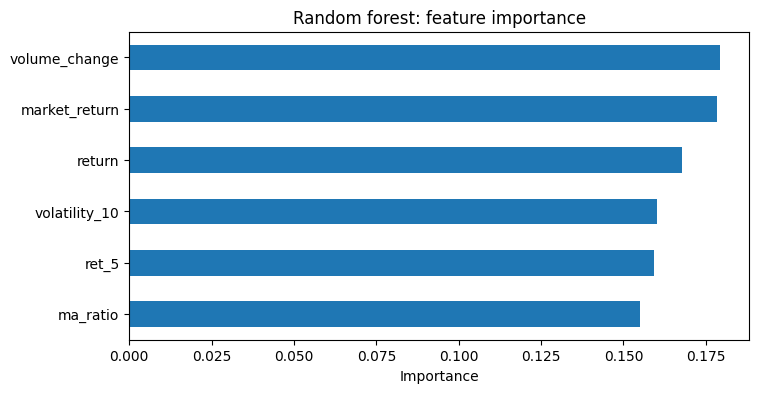

In [12]:
importance = pd.Series(rf_model.feature_importances_, index=features).sort_values()
importance.plot(kind='barh', figsize=(8, 4), title='Random forest: feature importance')
plt.xlabel('Importance')
plt.show()

## Findings: Improved Model

I added five new features: the 5-day return, price relative to its 20-day average, 10-day volatility, change in trading volume, and the whole market's daily return (average of all 505 stocks). I trained on the first 80% of dates (Mar 2013 – Feb 2017) and tested on the last 20% (Feb 2017 – Feb 2018, about 248 trading days).

| Model | Test accuracy |
|---|---|
| Always guess "up" (baseline) | 52.4% |
| Random forest | 51.6% |
| Logistic regression | 49.6% |

Neither model beat the baseline. With about 248 test days, one day changes accuracy by about 0.4 percentage points, so differences of a few points are within random variation. All three results are statistically indistinguishable.

This is consistent with the statistics section: daily returns show almost no autocorrelation, so price-based features carry very little information about the next day's direction. A more complex model does not help when the signal is not in the data.

Correlation of returns, yesterday vs today:          0.029
Correlation of size of moves, yesterday vs today:    0.127


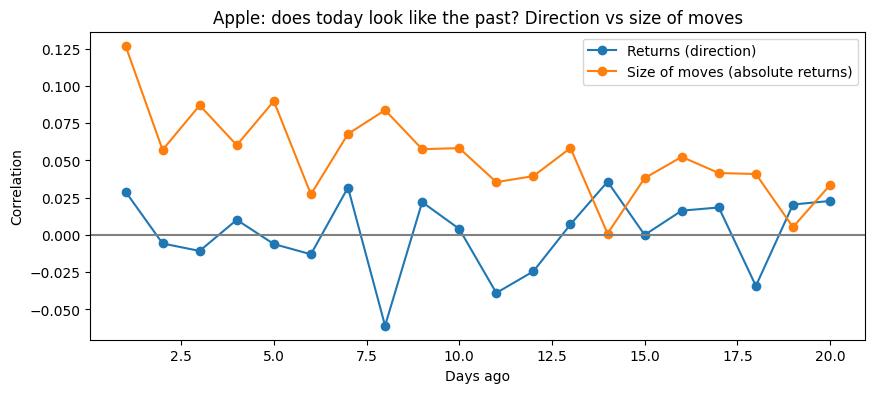

In [13]:
abs_ret = aapl.abs()   # size of each day's move, ignoring direction

print('Correlation of returns, yesterday vs today:         ', round(aapl.autocorr(1), 3))
print('Correlation of size of moves, yesterday vs today:   ', round(abs_ret.autocorr(1), 3))

lags = range(1, 21)
plt.figure(figsize=(10, 4))
plt.plot(lags, [aapl.autocorr(l) for l in lags], marker='o', label='Returns (direction)')
plt.plot(lags, [abs_ret.autocorr(l) for l in lags], marker='o', label='Size of moves (absolute returns)')
plt.axhline(0, color='grey')
plt.title('Apple: does today look like the past? Direction vs size of moves')
plt.xlabel('Days ago')
plt.ylabel('Correlation')
plt.legend()
plt.show()

In [14]:
v = data[data['Name'] == 'AAPL'].set_index('date').join(market)

v['abs_ret'] = v['return'].abs()                       # size of today's move
v['vol_5'] = v['return'].rolling(5).std()               # volatility over the last 5 days
v['vol_20'] = v['return'].rolling(20).std()             # ... last 20 days
v['vol_60'] = v['return'].rolling(60).std()             # ... last 60 days
v['market_abs'] = v['market_return'].abs()              # size of the whole market's move
v['volume_change'] = v['volume'].pct_change()
v['range'] = (v['high'] - v['low']) / v['close']        # today's high-low price range

# Target: volatility over the NEXT 5 trading days
v['target'] = v['return'].rolling(5).std().shift(-5)

v = v.dropna()
print(v.shape)
v[['abs_ret', 'vol_5', 'vol_20', 'range', 'target']].head()

(1194, 16)


,abs_ret,vol_5,vol_20,range,target
date,,,,,
2013-05-07,0.004453,0.013199,0.021578,0.026272,0.014217
2013-05-08,0.011298,0.010186,0.021303,0.020612,0.014447
2013-05-09,0.015242,0.015157,0.021667,0.016245,0.019382
2013-05-10,0.008320,0.015870,0.021604,0.020377,0.019623
2013-05-13,0.003908,0.010386,0.020719,0.014074,0.023853


In [15]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

features = ['abs_ret', 'vol_5', 'vol_20', 'vol_60', 'market_abs', 'volume_change', 'range']

split = int(len(v) * 0.8)
tr = v.iloc[:split - 5]   # leave a 5-day gap so training targets never use test-period days
te = v.iloc[split:]
y_te = te['target']

preds = {
    'Baseline: average volatility':     np.full(len(te), tr['target'].mean()),
    'Baseline: last 20 days volatility': te['vol_20'].values,
}

lin = LinearRegression().fit(tr[features], tr['target'])
preds['Linear regression'] = lin.predict(te[features])

rf = RandomForestRegressor(n_estimators=300, max_depth=4, random_state=42)
rf.fit(tr[features], tr['target'])
preds['Random forest'] = rf.predict(te[features])

print(f'Test period: {te.index.min().date()} to {te.index.max().date()}\n')
for name, p in preds.items():
    print(f'{name:36s} MAE = {mean_absolute_error(y_te, p):.5f}   R² = {r2_score(y_te, p):.3f}')

Test period: 2017-02-21 to 2018-01-31

Baseline: average volatility         MAE = 0.00510   R² = -0.196
Baseline: last 20 days volatility    MAE = 0.00473   R² = -0.330
Linear regression                    MAE = 0.00435   R² = -0.049
Random forest                        MAE = 0.00493   R² = -0.326


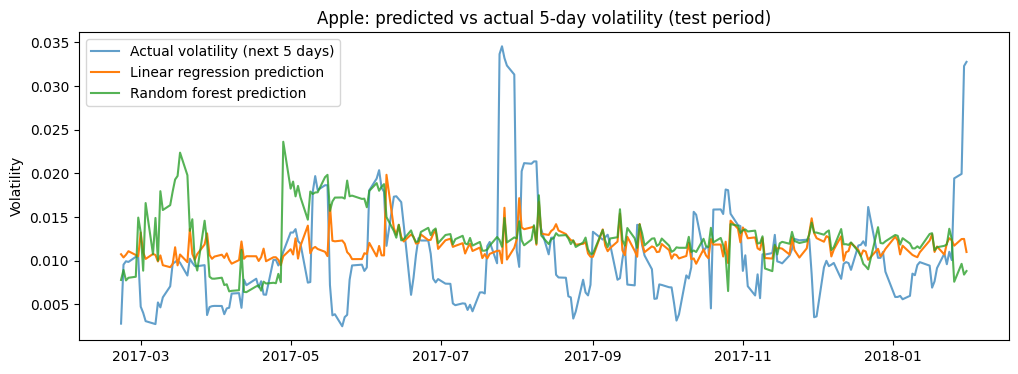

In [16]:
plt.figure(figsize=(12, 4))
plt.plot(te.index, y_te, label='Actual volatility (next 5 days)', alpha=0.7)
plt.plot(te.index, preds['Linear regression'], label='Linear regression prediction')
plt.plot(te.index, preds['Random forest'], label='Random forest prediction', alpha=0.8)
plt.title('Apple: predicted vs actual 5-day volatility (test period)')
plt.ylabel('Volatility')
plt.legend()
plt.show()

## Findings: Predicting Volatility

**1. The size of moves is predictable, even though the direction is not.**
For Apple, the correlation between yesterday's and today's return is only 0.029, but between yesterday's and today's *absolute* return it is 0.127, more than four times higher. The size of moves stays positively correlated for up to 20 days, while direction fluctuates randomly around zero. This is **volatility clustering**: big moves tend to follow big moves.

**2. Linear regression beat both baselines.**
Predicting volatility over the next 5 trading days (test period Feb 2017 – Jan 2018, with a 5-day gap between training and test data to prevent look-ahead bias):

| Method | MAE |
|---|---|
| Baseline: average volatility | 0.00510 |
| Baseline: last 20 days' volatility | 0.00473 |
| **Linear regression** | **0.00435** |
| Random forest | 0.00493 |

Linear regression reduced the average error by about 15% compared with the average baseline and about 8% compared with the 20-day baseline. The random forest performed worse than linear regression, likely because it overfitted to patterns in the training years.

**3. Why R² is negative.**
All methods have negative R² because 2017 was an unusually calm year: actual volatility was often around 0.005, while models trained on 2013–2016 predicted around 0.011. The models captured the *pattern* of volatility but not the lower overall *level*. This shows how a change in market conditions (a regime change) can affect models trained on past data.

**4. Missed spikes.**
The largest errors came from sudden spikes in early August 2017 and late January 2018, which are likely related to scheduled events such as quarterly earnings announcements. These cannot be predicted from past prices alone.

**Next steps:** add earnings-announcement dates as a feature, and use walk-forward validation so the model is regularly retrained on recent data.

## Conclusion

- Cleaned and explored 5 years of daily prices for 505 S&P 500 companies (619,029 rows).
- Daily returns are **not normally distributed**: Apple's returns have fat tails (excess kurtosis 3.77), with 19 extreme days compared with 3.4 expected under a normal distribution.
- **Direction is close to random:** day-to-day returns show almost no autocorrelation across all 505 stocks. Logistic regression and random forest models, even with volume, trend, volatility and market-wide features, did not beat a simple "always up" baseline (52.4%).
- **Volatility is partly predictable:** the size of moves shows clear clustering (lag-1 correlation 0.127 compared with 0.029 for direction). A linear regression model predicting next-week volatility beat both baselines, reducing average error by about 15%.
- **Limitations:** the test year (2017) was unusually calm, so all models overestimated the level of volatility (negative R²), and sudden spikes around scheduled events such as earnings were missed.
- **Main lesson:** in financial data, the useful question is often not *which way* prices will move but *how much*. Careful baselines, time-based splits and honest evaluation show where the real signal is.
- **Next steps:** add earnings-announcement dates as a feature, use walk-forward validation to retrain on recent data, and extend the analysis to all 505 stocks.